# Processamento da entrada (pizza) — `code_input.png`

Mesmo gráfico de `graphic/code/grafico_entrada_codigo.ipynb`. Os números vêm da coluna *Code route* de `../data/tabela_de_codigos_artefatos.csv` (cada estudo em uma categoria). Cores iguais às de `grafico_linguagem_codigo.ipynb` (`cores.py`).

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import dados_artefatos as da
from cores import ROTA   # código da entrada -> (rótulo, cor)

In [2]:
contagem = da.contagem("Code route")
ordem = sorted([c for c in ROTA if c != "CR4"], key=lambda c: -contagem[c]) + ["CR4"]   # decrescente, "Other" no fim
dados = [(ROTA[c][0], int(contagem[c]), ROTA[c][1]) for c in ordem]
labels_pizza = [d[0] for d in dados]
valores_pizza = [d[1] for d in dados]
cores_pizza = [d[2] for d in dados]

total = sum(valores_pizza)
print(contagem.to_dict(), "total =", total)
assert total == len(da.estudos("Code route"))
percentuais = [round(v / total * 100) for v in valores_pizza]

{'CR1': 90, 'CR2': 82, 'CR3': 56, 'CR4': 47} total = 275


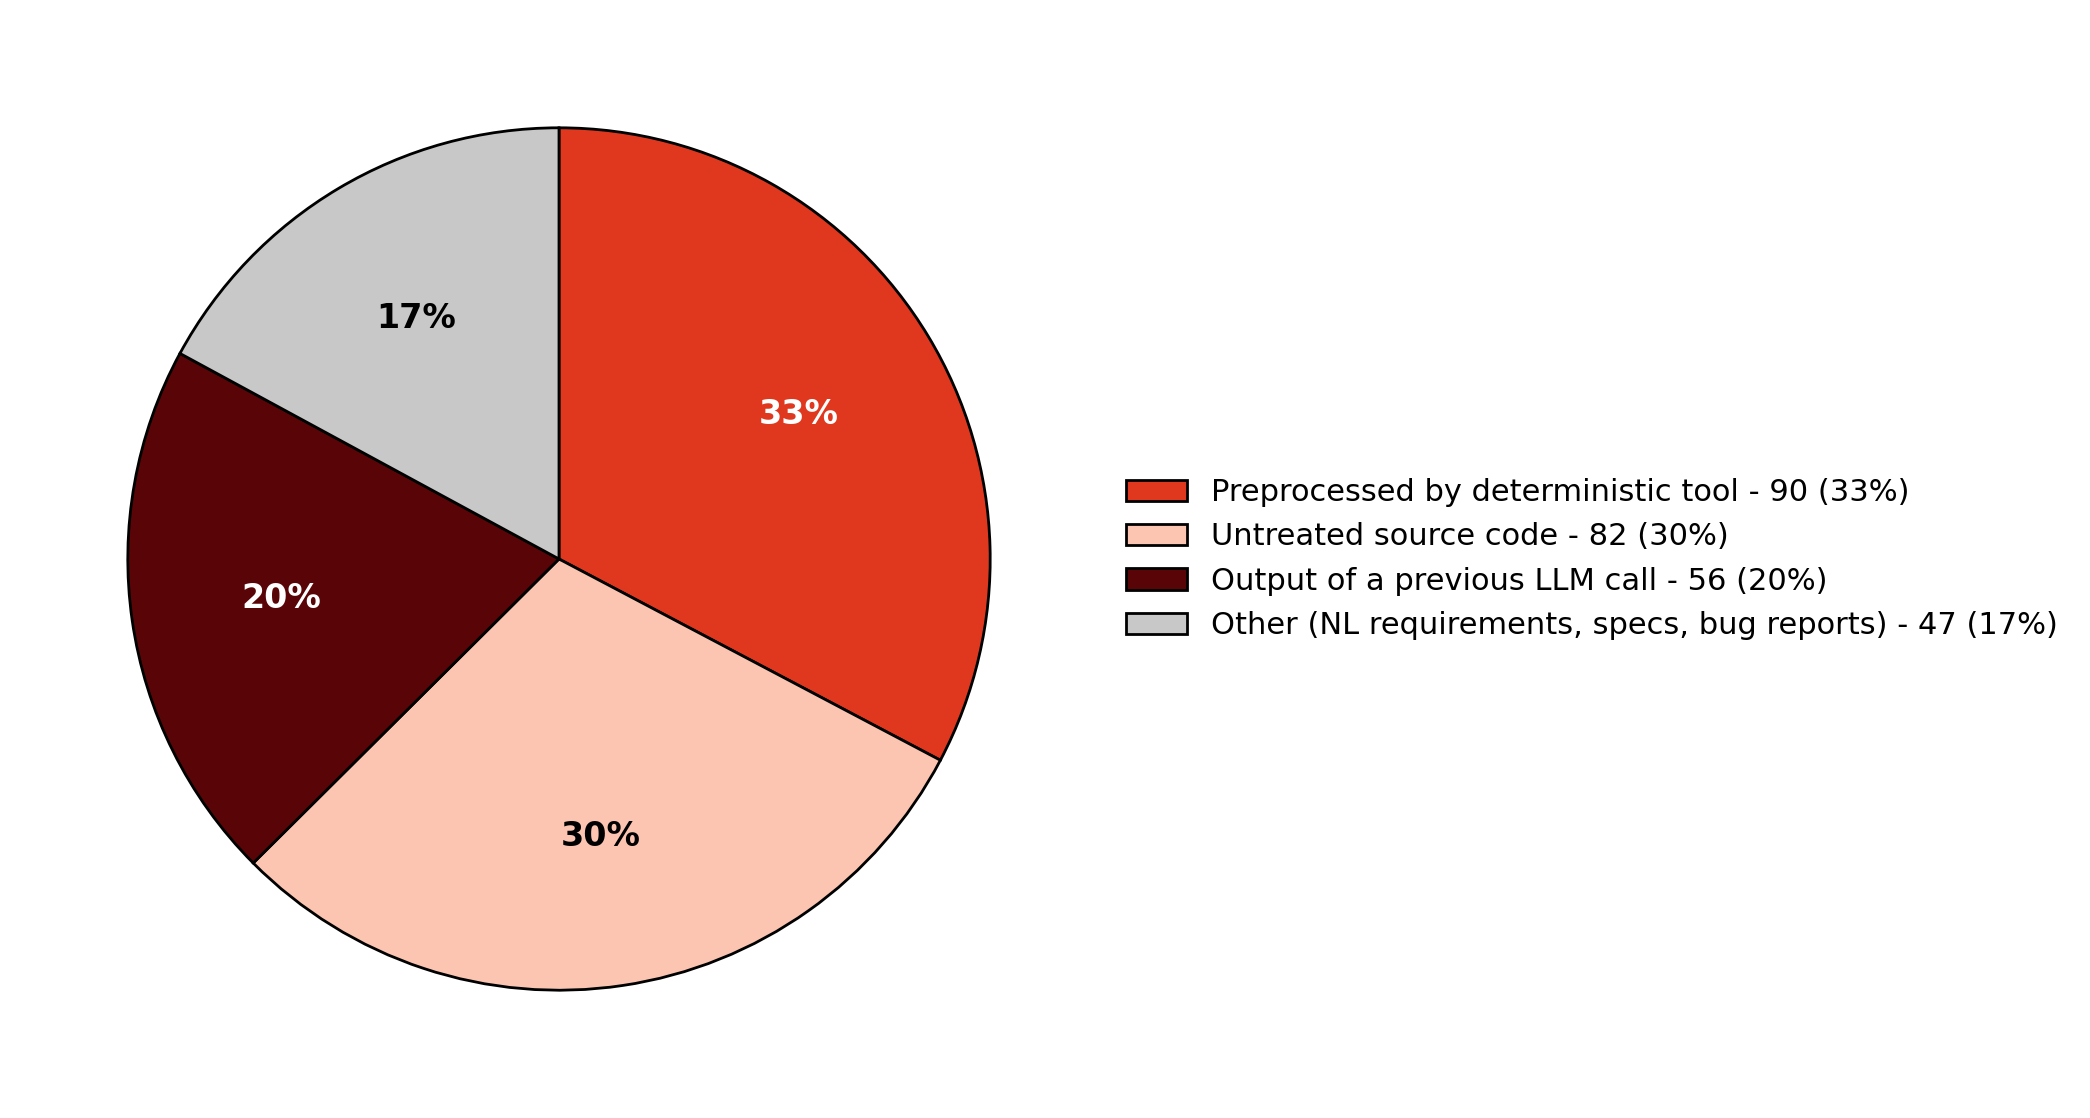

In [3]:
def cor_texto_legivel(rgba):
    r, g, b, _ = rgba
    return "black" if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"

fig, ax = plt.subplots(figsize=(10, 7), dpi=200)

wedges, _ = ax.pie(
    valores_pizza,
    colors=cores_pizza,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "black", "linewidth": 1},
)
# porcentagem dentro de cada fatia
for w, pct in zip(wedges, percentuais):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    ax.text(0.65 * np.cos(ang), 0.65 * np.sin(ang), f"{pct}%", ha="center", va="center",
            fontsize=12, fontweight="bold", color=cor_texto_legivel(w.get_facecolor()))

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", label=f"{l} - {v} ({p}%)")
    for l, cor, v, p in zip(labels_pizza, cores_pizza, valores_pizza, percentuais)
]
ax.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.0, 0.5),
          frameon=False, fontsize=11)

ax.set_aspect("equal")
ax.axis("off")

plt.savefig("code_input.png", bbox_inches="tight", dpi=200)
plt.savefig("code_input.pdf", bbox_inches="tight")
plt.show()